# **LAB03: CÀI ĐẶT VÀ SO SÁNH CÁC BỘ PHÂN LỚP TUYẾN TÍNH**
## **Linear Classifiers: Perceptron, Logistic Regression, Linear SVM**

> **Họ tên: Vương Thành Đạt - MSSV: 24280058**


---
## 0. Tổng quan lý thuyết và Chuẩn bị môi trường

### 0.1. Bộ phân lớp tuyến tính là gì?
Trong bài toán nhận dạng mẫu nhị phân, ta có tập huấn luyện gồm $N$ mẫu:
$$\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^N, \quad \mathbf{x}_i \in \mathbb{R}^d, \quad y_i \in \{-1, +1\}$$

Một **bộ phân lớp tuyến tính** (Linear Classifier) tìm cách phân tách hai lớp dữ liệu bằng một **siêu phẳng** (hyperplane):
$$\mathcal{H} = \{\mathbf{x} \in \mathbb{R}^d \mid \mathbf{w}_0^\top \mathbf{x} + b = 0\}$$

* Trong không gian 2 chiều ($d=2$), siêu phẳng là một đường thẳng $w_1 x_1 + w_2 x_2 + b = 0$.
* Trong không gian 3 chiều ($d=3$), siêu phẳng là một mặt phẳng $w_1 x_1 + w_2 x_2 + w_3 x_3 + b = 0$.
* Trong không gian $d$ chiều, siêu phẳng là một không gian con $(d-1)$ chiều chia không gian đặc trưng thành hai nửa:
  * Nửa dương ($y = +1$): $\mathbf{w}_0^\top \mathbf{x} + b > 0$
  * Nửa âm ($y = -1$): $\mathbf{w}_0^\top \mathbf{x} + b < 0$

**Hàm quyết định (Decision Function):**
$$g(\mathbf{x}) = \mathbf{w}_0^\top \mathbf{x} + b$$
Quy tắc dự đoán nhãn: $\hat{y} = \operatorname{sign}(g(\mathbf{x}))$.

**Đại lượng lề hàm số (Functional Margin):**
Với mẫu $(\mathbf{x}_i, y_i)$, tích $y_i g(\mathbf{x}_i) = y_i(\mathbf{w}_0^\top \mathbf{x}_i + b)$ cho biết:
* $y_i g(\mathbf{x}_i) > 0$: Mẫu được phân lớp đúng.
* $y_i g(\mathbf{x}_i) \le 0$: Mẫu bị phân lớp sai (hoặc nằm đúng trên ranh giới).


### 0.2. Kỹ thuật Vector mở rộng (Bias Trick)
Trong công thức gốc, ta phải quản lý đồng thời hai biến: vector trọng số $\mathbf{w}_0 \in \mathbb{R}^d$ và hệ số tự do $b \in \mathbb{R}$.

Để tính toán ma trận gọn gàng và hiệu quả, ta bổ sung thêm giá trị $1$ vào cuối vector đặc trưng:
$$\tilde{\mathbf{x}} = [\mathbf{x}; 1] = [x_1, x_2, \dots, x_d, 1]^\top \in \mathbb{R}^{d+1}$$
$$\mathbf{w} = [\mathbf{w}_0; b] = [w_1, w_2, \dots, w_d, b]^\top \in \mathbb{R}^{d+1}$$

Khi đó, phương trình siêu phẳng trở thành một tích vô hướng duy nhất:
$$g(\mathbf{x}) = \mathbf{w}^\top \tilde{\mathbf{x}} = 0$$


In [1]:
import time
import warnings
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.exceptions import ConvergenceWarning

# Bỏ qua các cảnh báo hội tụ lặp lại để giữ notebook gọn gàng
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Cấu hình hạt giống và tham số thí nghiệm dùng chung
SEED = 0            # seed mặc định dùng cho các thử nghiệm đơn lẻ
TEST_SIZE = 0.3     # tỉ lệ tập test cố định cho toàn bài (70% train, 30% test)
SEEDS = range(10)   # 10 cách chia khác nhau dùng để đánh giá thống kê

# Bảng màu và ký hiệu nhất quán cho các lớp dữ liệu
CLASS_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c"]
BG_COLORS = ["#aec7e8", "#ffbb78", "#98df8a"]
CLASS_MARKERS = ["o", "s", "^"]


### 0.3. Định nghĩa các hàm tiện ích hỗ trợ
1. `add_bias(X)`: Thêm một cột chứa toàn số $1$ vào cuối ma trận đặc trưng $X \in \mathbb{R}^{N \times d} \to \tilde{X} \in \mathbb{R}^{N \times (d+1)}$.
2. `plot_data(ax, X, y)`: Vẽ biểu đồ phân tán 2D các điểm dữ liệu theo từng lớp.
3. `plot_decision_boundary(ax, model, X, y)`: Quét lưới điểm không gian (resolution 300x300) để vẽ đường phân cách $g(\mathbf{x}) = 0$, đường lề $g(\mathbf{x}) = \pm 1$ (với SVM), hoặc vùng tô màu đa lớp.


In [2]:
def add_bias(X):
    """Bổ sung cột 1 vào cuối ma trận đặc trưng"""
    return np.hstack([X, np.ones((X.shape[0], 1))])


def plot_data(ax, X, y, title="", labels=None):
    """Vẽ dữ liệu 2D với màu và marker theo từng lớp."""
    classes = np.unique(y)
    for i, c in enumerate(classes):
        mask = y == c
        lbl = labels[i] if labels is not None else f"Lớp {c}"
        ax.scatter(X[mask, 0], X[mask, 1], c=CLASS_COLORS[i % len(CLASS_COLORS)],
                   marker=CLASS_MARKERS[i % len(CLASS_MARKERS)], edgecolors="k",
                   linewidths=0.5, s=30, label=lbl)
    ax.set_title(title)
    ax.legend(fontsize=8, frameon=True, facecolor="white", framealpha=0.85, edgecolor="none")


def plot_decision_boundary(ax, model, X, y, title="", show_margin=False, resolution=300):
    """Vẽ ranh giới quyết định (và đường lề nếu show_margin=True) trên ax."""
    plot_data(ax, X, y, title=title)
    x0_min, x0_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x1_min, x1_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx0, xx1 = np.meshgrid(np.linspace(x0_min, x0_max, resolution),
                           np.linspace(x1_min, x1_max, resolution))
    grid = np.c_[xx0.ravel(), xx1.ravel()]
    classes = np.unique(y)
    n_classes = len(classes)

    if n_classes == 2:
        # Đường ranh giới g(x) = 0 và hai đường lề g(x) = ±1
        zz = model.decision_function(grid).reshape(xx0.shape)
        ax.contour(xx0, xx1, zz, levels=[0.0], colors="k", linewidths=1.5)
        if show_margin:
            ax.contour(xx0, xx1, zz, levels=[-1.0, 1.0], colors="k",
                       linestyles="--", linewidths=1.0)
    else:
        # Tô màu nền theo lớp được gán
        pred = model.predict(grid).reshape(xx0.shape)
        class_to_idx = {c: i for i, c in enumerate(classes)}
        grid_idx = np.vectorize(class_to_idx.get)(pred)
        from matplotlib.colors import ListedColormap
        ax.contourf(xx0, xx1, grid_idx, levels=[-0.5, 0.5, 1.5, 2.5][:n_classes + 1],
                    colors=BG_COLORS[:n_classes], alpha=0.35)
        # Các đường biên giữa các vùng
        for k in range(n_classes):
            score_k = model.decision_function(grid)[:, k].reshape(xx0.shape)
            other_max = np.delete(model.decision_function(grid), k, axis=1).max(axis=1).reshape(xx0.shape)
            ax.contour(xx0, xx1, score_k - other_max, levels=[0.0], colors="k", linewidths=1.0)


---
## 1. Dữ liệu thực nghiệm và Tiền xử lý

### 1.1. Giới thiệu các tập dữ liệu thực nghiệm

| Ký hiệu | Mô tả | Số mẫu ($N$) | Số đặc trưng ($d$) | Số lớp ($K$) | Ý nghĩa thực nghiệm |
|---|---|---|---|---|---|
| **D1** | Hai đám mây Gauss tách biệt | 200 | 2 | 2 | Dữ liệu tách được tuyến tính hoàn hảo (Linearly Separable) |
| **D2** | Hai đám mây Gauss chồng lấn | 200 | 2 | 2 | Dữ liệu không tách được tuyến tính (Overlapping / Non-separable) |
| **D3a** | Dữ liệu Wine (chỉ lấy 2 đặc trưng) | 178 | 2 | 3 | Bài toán đa lớp trên không gian 2D để trực quan hóa |
| **D3b** | Dữ liệu Wine (đầy đủ 13 đặc trưng) | 178 | 13 | 3 | Bài toán đa lớp thực tế nhiều chiều, thang đo chênh lệch |


In [3]:
# Sinh dữ liệu Gauss giả lập D1 và D2
rng = np.random.default_rng(SEED)

# D1: hai cụm Gauss cách xa nhau
X_d1 = np.vstack([
    rng.normal([-1.5, 0], 0.6, (100, 2)),
    rng.normal([1.5, 0], 0.6, (100, 2))
])
y_d1 = np.array([-1] * 100 + [1] * 100)

# D2: hai cụm Gauss có hiệp phương sai lệch và chồng lấn nhau
cov_d2 = [[0.8, 0.4], [0.4, 0.8]]
X_d2 = np.vstack([
    rng.multivariate_normal([1, 1], cov_d2, 100),
    rng.multivariate_normal([-1, -1], cov_d2, 100)
])
y_d2 = np.array([-1] * 100 + [1] * 100)

# D3: bộ dữ liệu thực tế Wine
wine = load_wine()
X_d3a = wine.data[:, :2]  # chỉ lấy 2 đặc trưng đầu: alcohol và malic_acid
X_d3b = wine.data        # đủ 13 đặc trưng hóa sinh
y_d3 = wine.target

DATASETS = {
    "D1": (X_d1, y_d1),
    "D2": (X_d2, y_d2),
    "D3a": (X_d3a, y_d3),
    "D3b": (X_d3b, y_d3),
}


### 1.2. Trực quan hóa dữ liệu trên không gian 2D ($D_1$, $D_2$, $D_{3a}$)
Quan sát sự phân bố hình học của các đám mây điểm trước khi đưa vào mô hình học máy:


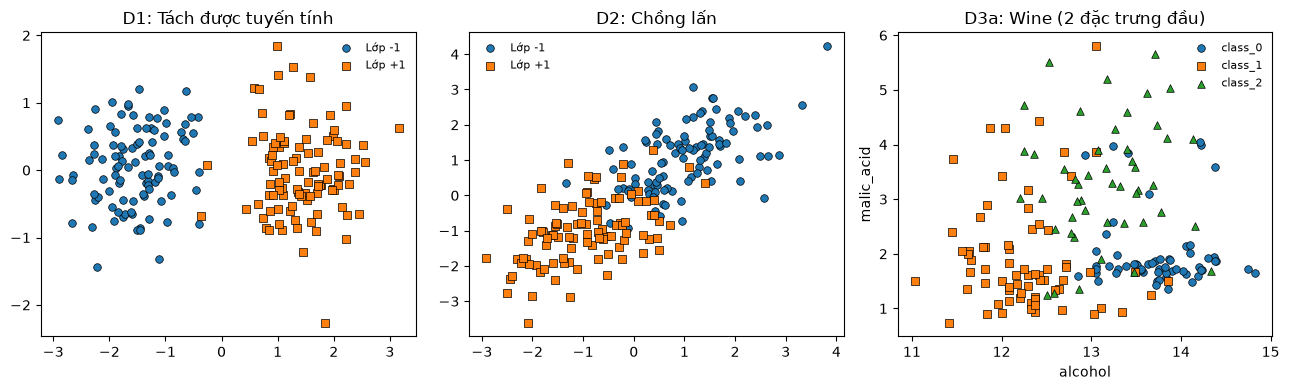

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
plot_data(axes[0], X_d1, y_d1, title="D1: Tách được tuyến tính", labels=["Lớp -1", "Lớp +1"])
plot_data(axes[1], X_d2, y_d2, title="D2: Chồng lấn", labels=["Lớp -1", "Lớp +1"])
plot_data(axes[2], X_d3a, y_d3, title="D3a: Wine (2 đặc trưng đầu)", labels=wine.target_names)
axes[2].set(xlabel=wine.feature_names[0], ylabel=wine.feature_names[1])
plt.tight_layout()
plt.show()


### 1.3. Chuẩn hóa đặc trưng (Z-Score Standardization) và Hiện tượng Rò rỉ dữ liệu

#### Tại sao phải chuẩn hóa dữ liệu?
Trong các bộ dữ liệu thực tế (như tập Wine), các đặc trưng có thang đo rất khác nhau: ví dụ hàm lượng Proline có giá trị từ 200 đến 1700, trong khi độ axit Malic chỉ từ 0.7 đến 5.8.
* Nếu không chuẩn hóa, đặc trưng có thang đo lớn sẽ áp đảo hoàn toàn hàm mất mát và gradient.
* Các thuật toán có số hạng phạt điều chuẩn $L_2$ ($\frac{\lambda}{2}\|\mathbf{w}\|^2$) sẽ vô tình phạt nặng các trọng số của đặc trưng có thang đo nhỏ, khiến mô hình hoạt động kém.

#### Công thức chuẩn hóa Z-Score:
$$z = \frac{x - \mu}{\sigma}$$
Trong đó $\mu$ là trung bình và $\sigma$ là độ lệch chuẩn theo từng cột đặc trưng. Nếu $\sigma = 0$ (cột hằng số), ta đặt $\sigma = 1$ để tránh lỗi chia cho 0.

#### Tránh rò rỉ dữ liệu (Data Leakage):
Tham số $\mu$ và $\sigma$ **bắt buộc phải được tính duy nhất trên tập Train**. Sau đó, ta dùng đúng $\mu$ và $\sigma$ này để biến đổi tập Test. Tuyệt đối không tính $\mu, \sigma$ trên toàn bộ dữ liệu trước khi chia tập.


In [5]:
class Standardizer:
    """Chuẩn hóa z-score, tham số học từ tập train."""

    def fit(self, X):
        # Tính mean và std theo từng cột
        self.mean_ = np.mean(X, axis=0)
        self.std_ = np.std(X, axis=0)
        # Xử lý trường hợp đặc trưng hằng số (std = 0) thì giữ nguyên giá trị
        self.std_ = np.where(self.std_ == 0, 1.0, self.std_)
        return self
        
    def transform(self, X):
        # Trả về ma trận chuẩn hóa: (X - mean) / std
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


### 1.4. Chia tập và Chuẩn hóa dữ liệu (`split_and_scale`)
Hàm `split_and_scale` thực hiện chia tập phân tầng (`stratify=y`) đảm bảo tỉ lệ các lớp ở tập Train và Test đồng nhất, sau đó chuẩn hóa theo đúng nguyên tắc chống rò rỉ dữ liệu.


In [6]:
def split_and_scale(X, y, seed, scale=True):
    """Chia train/test có phân tầng; chuẩn hóa theo thống kê của tập train."""
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=seed
    )
    if scale:
        scaler = Standardizer().fit(X_tr)
        X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)
    return X_tr, X_te, y_tr, y_te


# Kiểm chứng trên tập Wine D3b
X_tr, X_te, y_tr, y_te = split_and_scale(X_d3b, y_d3, SEED)
print("Kích thước tập Train:", X_tr.shape, "| Kích thước tập Test:", X_te.shape)
print("Trung bình 4 cột đầu tập Train (xấp xỉ 0):", np.round(X_tr.mean(axis=0)[:4], 3))
print("Độ lệch chuẩn 4 cột đầu tập Train (xấp xỉ 1):", np.round(X_tr.std(axis=0)[:4], 3))


Kích thước tập Train: (124, 13) | Kích thước tập Test: (54, 13)
Trung bình 4 cột đầu tập Train (xấp xỉ 0): [0. 0. 0. 0.]
Độ lệch chuẩn 4 cột đầu tập Train (xấp xỉ 1): [1. 1. 1. 1.]


---
## 2. Cài đặt các Bộ phân lớp tuyến tính bằng NumPy (From Scratch)

### 2.1. Thuật toán Perceptron (Rosenblatt, 1958)

#### Bản chất và Cơ chế hoạt động:
Perceptron là thuật toán phân lớp tuyến tính nhị phân dựa trên nguyên lý **học trực tuyến theo mẫu sai** (Error-driven Online Learning):
* Khởi tạo vector trọng số ban đầu $\mathbf{w} = \mathbf{0}$.
* Lần lượt duyệt qua từng mẫu dữ liệu $(\mathbf{x}_i, y_i)$ trong mỗi epoch.
* Với mẫu thứ $i$, tính giá trị lề hàm số: $y_i (\mathbf{w}^\top \tilde{\mathbf{x}}_i)$.
  * Nếu $y_i (\mathbf{w}^\top \tilde{\mathbf{x}}_i) > 0$: Mẫu đã được **phân lớp đúng**, ta **giữ nguyên $\mathbf{w}$**.
  * Nếu $y_i (\mathbf{w}^\top \tilde{\mathbf{x}}_i) \le 0$: Mẫu bị **phân lớp sai**, ta **cập nhật $\mathbf{w}$**:
    $$\mathbf{w} \leftarrow \mathbf{w} + \rho \, y_i \, \tilde{\mathbf{x}}_i$$
    Trong đó $\rho > 0$ là tốc độ học (learning rate).

#### Ý nghĩa hình học của bước cập nhật:
Khi cộng thêm $\rho y_i \tilde{\mathbf{x}}_i$, vector pháp tuyến $\mathbf{w}$ được kéo xoay về phía mẫu $\tilde{\mathbf{x}}_i$, làm cho tích vô hướng $y_i(\mathbf{w}^\top \tilde{\mathbf{x}}_i)$ tăng lên trong các lần duyệt sau.

#### Điều kiện dừng:
Thuật toán dừng khi duyệt hết một epoch mà **không có mẫu nào bị sai** ($n\_err = 0$), hoặc khi đã chạm số vòng lặp tối đa `max_epochs`.


In [7]:
class PerceptronNP:
    """Perceptron, nhãn y ∈ {−1, +1}."""

    def __init__(self, rho=1.0, max_epochs=100, shuffle=True, seed=0):
        self.rho = rho
        self.max_epochs = max_epochs
        self.shuffle = shuffle
        self.seed = seed

    def fit(self, X, y):
        Xb = add_bias(X)
        rng = np.random.default_rng(self.seed)
        self.w_ = np.zeros(Xb.shape[1])
        self.errors_ = []                      # số mẫu sai trong từng epoch
        for epoch in range(self.max_epochs):
            order = rng.permutation(len(y)) if self.shuffle else np.arange(len(y))
            n_err = 0
            for i in order:
                # Kiểm tra điều kiện mẫu bị phân lớp sai
                if y[i] * (Xb[i] @ self.w_) <= 0:
                    self.w_ += self.rho * y[i] * Xb[i]
                    n_err += 1
            self.errors_.append(n_err)
            if n_err == 0:
                break
        self.n_epochs_ = len(self.errors_)
        return self

    def decision_function(self, X):
        return add_bias(X) @ self.w_

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)


### 2.1.2. Kiểm nghiệm Perceptron trên $D_1$ và $D_2$


In [8]:
for name in ["D1", "D2"]:
    X, y = DATASETS[name]
    X_tr, X_te, y_tr, y_te = split_and_scale(X, y, SEED)
    p = PerceptronNP(seed=SEED).fit(X_tr, y_tr)
    print(f"{name}: Dừng sau {p.n_epochs_:3d} epoch, "
          f"số mẫu sai ở epoch cuối = {p.errors_[-1]:2d}, "
          f"Acc train = {accuracy_score(y_tr, p.predict(X_tr)):.3f}, "
          f"Acc test = {accuracy_score(y_te, p.predict(X_te)):.3f}")


D1: Dừng sau   8 epoch, số mẫu sai ở epoch cuối =  0, Acc train = 1.000, Acc test = 1.000
D2: Dừng sau 100 epoch, số mẫu sai ở epoch cuối = 18, Acc train = 0.843, Acc test = 0.767


---
### 2.2. Thuật toán Hồi quy Logistic (Logistic Regression)

#### Bản chất và Xác suất đầu ra:
Khác với Perceptron chỉ đưa ra nhãn cứng, Hồi quy Logistic ước lượng **xác suất hậu nghiệm** của nhãn:
$$p(y = +1 \mid \mathbf{x}) = \sigma(z), \quad \text{với } z = \mathbf{w}^\top \tilde{\mathbf{x}}$$
Hàm kích hoạt Sigmoid chuyển đổi điểm số thực $z \in (-\infty, +\infty)$ về khoảng xác suất $(0, 1)$:
$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

#### Ổn định số học cho hàm Sigmoid:
* Khi $z \ll 0$, đại lượng $e^{-z}$ có thể vượt quá giới hạn biểu diễn của số thực dấu phẩy động 64-bit (`float64`), gây lỗi tràn số (*Overflow*).
* Do đó, ta tính toán ổn định số học theo hai nhánh:
  $$\sigma(z) = \begin{cases} \frac{1}{1 + e^{-z}} & \text{nếu } z \ge 0 \\ \frac{e^z}{1 + e^z} & \text{nếu } z < 0 \end{cases}$$

#### Hàm mất mát Cross-Entropy có điều chuẩn L2:
Đổi nhãn từ $\{-1, +1\}$ sang $\{0, 1\}$ bằng công thức $t_i = (y_i + 1)/2$. Hàm mất mát là:
$$J(\mathbf{w}) = \frac{1}{N}\sum_{i=1}^{N} \Big[\log\big(1 + e^{z_i}\big) - t_i z_i\Big] + \frac{\lambda}{2}\big\lVert \mathbf{w}_{1:d} \big\rVert^2$$
* Lưu ý quan trọng: Ta **không điều chuẩn hệ số bias** (thành phần cuối $w_{d+1}$), vì việc phạt bias sẽ ép siêu phẳng phân cách phải đi qua gần gốc tọa độ một cách gượng ép.
* Đại lượng $\log(1 + e^{z_i})$ được tính toán chống tràn số bằng hàm `np.logaddexp(0, z)`.

#### Gradient và Cập nhật:
$$\nabla J = \frac{1}{N}\tilde{\mathbf{X}}^\top(\mathbf{p} - \mathbf{t}) + \lambda\, (\mathbf{m} \odot \mathbf{w})$$
Trong đó $\mathbf{p} = \sigma(\tilde{\mathbf{X}}\mathbf{w})$, và $\mathbf{m} = [1, 1, \dots, 1, 0]^\top$ là mặt nạ loại trừ bias.
Cập nhật theo Gradient Descent: $\mathbf{w} \leftarrow \mathbf{w} - \eta \nabla J$.


In [9]:
def sigmoid(z):
    """σ(z) tính ổn định số học cho cả z rất lớn và rất âm."""
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


class LogisticRegressionNP:
    """Logistic Regression nhị phân, gradient descent, điều chuẩn L2 (không phạt bias)."""

    def __init__(self, eta=0.5, lam=1e-3, max_epochs=2000, tol=1e-7):
        self.eta = eta
        self.lam = lam
        self.max_epochs = max_epochs
        self.tol = tol

    def fit(self, X, y):
        Xb = add_bias(X)
        t = (y > 0).astype(float)              # chuyển nhãn {-1, +1} sang {0, 1}
        N, d = Xb.shape
        mask = np.ones(d)
        mask[-1] = 0.0                         # mask đặt 0 cho vị trí bias (không phạt)
        self.w_ = np.zeros(d)
        self.loss_ = []                        # lưu vết hàm mất mát J(w)
        
        for epoch in range(self.max_epochs):
            # 1. Tính điểm thô z và xác suất p
            z = Xb @ self.w_
            p = sigmoid(z)
            
            # 2. Tính hàm mất mát Cross-Entropy có L2
            loss = np.mean(np.logaddexp(0, z) - t * z) + 0.5 * self.lam * np.sum(self.w_[:-1] ** 2)
            
            # 3. Tính gradient trên toàn tập dữ liệu
            grad = (Xb.T @ (p - t)) / N + self.lam * (mask * self.w_)
            
            # 4. Cập nhật vector trọng số
            self.w_ -= self.eta * grad
            self.loss_.append(loss)
            
            # Điều kiện dừng sớm khi hàm mất mát hội tụ
            if epoch > 0 and abs(self.loss_[-2] - loss) < self.tol:
                break
        return self

    def decision_function(self, X):
        return add_bias(X) @ self.w_

    def predict_proba(self, X):
        """Xác suất p(y = +1 | x)."""
        return sigmoid(self.decision_function(X))

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)


### 2.2.2. Kiểm nghiệm Logistic Regression trên $D_1$ và $D_2$


In [10]:
for name in ["D1", "D2"]:
    X, y = DATASETS[name]
    X_tr, X_te, y_tr, y_te = split_and_scale(X, y, SEED)
    lr = LogisticRegressionNP().fit(X_tr, y_tr)
    print(f"{name}: Dừng sau {len(lr.loss_):4d} epoch, "
          f"J cuối = {lr.loss_[-1]:.4f}, "
          f"Acc test = {accuracy_score(y_te, lr.predict(X_te)):.3f}, "
          f"P(y=+1|x) 3 mẫu đầu = {np.round(lr.predict_proba(X_te[:3]), 3)}")


D1: Dừng sau 1380 epoch, J cuối = 0.0444, Acc test = 0.983, P(y=+1|x) 3 mẫu đầu = [0.007 0.991 0.002]
D2: Dừng sau  410 epoch, J cuối = 0.2390, Acc test = 0.933, P(y=+1|x) 3 mẫu đầu = [0.023 0.994 0.   ]


---
### 2.3. Thuật toán Máy vector hỗ trợ tuyến tính (Linear SVM)

#### Nguyên lý lề cực đại (Maximum Margin):
SVM tìm siêu phẳng phân cách sao cho **khoảng cách hình học** tới các điểm dữ liệu gần nhất của hai lớp là lớn nhất. Khoảng cách lề hình học là:
$$\text{Margin} = \frac{2}{\lVert \mathbf{w}_0 \rVert}$$
Tối đa hóa lề tương đương với việc tối thiểu hóa $\frac{1}{2}\lVert \mathbf{w}_0 \rVert^2$.

#### Bài toán SVM lề mềm (Soft-Margin SVM) dạng Primal:
Với dữ liệu có thể chồng lấn, ta cho phép một số mẫu vi phạm lề với chi phí phạt là hàm **Hinge Loss**:
$$\min_{\mathbf{w}} \; \frac{\lambda}{2}\lVert \mathbf{w} \rVert^2 + \frac{1}{N}\sum_{i=1}^N \max\big(0, \, 1 - y_i \mathbf{w}^\top \tilde{\mathbf{x}}_i\big)$$

#### Thuật toán Pegasos (Shalev-Shwartz et al., 2011):
Pegasos (Primal Estimated sub-GrAdient SOlver for SVM) giải trực tiếp bài toán dạng Primal bằng phương pháp **Mini-batch Subgradient Descent kết hợp phép chiếu hình cầu**:
1. Ở mỗi bước lặp $t \in [1, T]$, chọn ngẫu nhiên một mini-batch gồm $k$ mẫu: $\mathcal{A}_t \subset \{1, \dots, N\}$.
2. Tốc độ học giảm dần theo thời gian:
   $$\eta_t = \frac{1}{\lambda t}$$
3. Xác định tập các mẫu trong batch bị **vi phạm lề**:
   $$\mathcal{A}_t^+ = \{i \in \mathcal{A}_t \mid y_i (\mathbf{w}^\top \tilde{\mathbf{x}}_i) < 1\}$$
4. Cập nhật vector trọng số theo subgradient:
   $$\mathbf{w}_{t+1/2} = (1 - \eta_t \lambda)\mathbf{w}_t + \frac{\eta_t}{k} \sum_{i \in \mathcal{A}_t^+} y_i \tilde{\mathbf{x}}_i$$
5. **Phép chiếu hình cầu (Projection step)**: Chiếu $\mathbf{w}$ về hình cầu bán kính $1/\sqrt{\lambda}$:
   $$\mathbf{w}_{t+1} = \min\left(1, \frac{1/\sqrt{\lambda}}{\lVert \mathbf{w}_{t+1/2} \rVert}\right) \mathbf{w}_{t+1/2}$$


In [11]:
class LinearSVMNP:
    """SVM tuyến tính lề mềm, giải dạng primal bằng Pegasos mini batch."""

    def __init__(self, lam=1e-2, n_iters=3000, batch_size=16, project=True, seed=0, log_every=10):
        self.lam = lam
        self.n_iters = n_iters
        self.batch_size = batch_size
        self.project = project
        self.seed = seed
        self.log_every = log_every

    def objective(self, Xb, y):
        """Hàm mục tiêu (λ/2)‖w‖² + trung bình hinge loss."""
        hinge = np.maximum(0.0, 1.0 - y * (Xb @ self.w_))
        return 0.5 * self.lam * (self.w_ @ self.w_) + hinge.mean()

    def fit(self, X, y):
        Xb = add_bias(X)
        N, d = Xb.shape
        k = min(self.batch_size, N)
        rng = np.random.default_rng(self.seed)
        self.w_ = np.zeros(d)
        self.obj_ = []                         # (t, giá trị hàm mục tiêu trên tập train)
        
        for t in range(1, self.n_iters + 1):
            idx = rng.choice(N, size=k, replace=False)
            Xt, yt = Xb[idx], y[idx]
            
            # Tốc độ học giảm dần
            eta_t = 1.0 / (self.lam * t)
            
            # Tập mẫu vi phạm lề trong batch: y_i w^T x_i < 1
            margin_violation = (yt * (Xt @ self.w_)) < 1.0
            grad_hinge = (Xt[margin_violation].T @ yt[margin_violation]) / k
            
            # Cập nhật trọng số
            self.w_ = (1.0 - eta_t * self.lam) * self.w_ + eta_t * grad_hinge
            
            # Phép chiếu về quả cầu bán kính 1 / sqrt(lambda)
            if self.project:
                norm_w = np.linalg.norm(self.w_)
                radius = 1.0 / np.sqrt(self.lam)
                if norm_w > radius:
                    self.w_ = (radius / norm_w) * self.w_
                    
            if t == 1 or t % self.log_every == 0:
                self.obj_.append((t, self.objective(Xb, y)))
        return self

    def decision_function(self, X):
        return add_bias(X) @ self.w_

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

    def support_vector_mask(self, X, y, tol=1e-3):
        """Mẫu nằm trên hoặc bên trong lề: y g(x) ≤ 1."""
        return y * self.decision_function(X) <= 1.0 + tol

    def margin_width(self):
        """Độ rộng lề hình học 2 / ‖w_{1:d}‖ (bỏ trọng số bias)."""
        return 2.0 / np.linalg.norm(self.w_[:-1])


### 2.3.2. Kiểm nghiệm Linear SVM trên $D_1$ và $D_2$


In [12]:
for name in ["D1", "D2"]:
    X, y = DATASETS[name]
    X_tr, X_te, y_tr, y_te = split_and_scale(X, y, SEED)
    svm = LinearSVMNP(seed=SEED).fit(X_tr, y_tr)
    n_sv = svm.support_vector_mask(X_tr, y_tr).sum()
    print(f"{name}: Mục tiêu cuối = {svm.obj_[-1][1]:.4f}, "
          f"Số Support Vectors = {n_sv:3d}/{len(y_tr)}, "
          f"Độ rộng lề = {svm.margin_width():.3f}, "
          f"Acc test = {accuracy_score(y_te, svm.predict(X_te)):.3f}")


D1: Mục tiêu cuối = 0.0540, Số Support Vectors =  11/140, Độ rộng lề = 0.864, Acc test = 0.983
D2: Mục tiêu cuối = 0.2696, Số Support Vectors =  40/140, Độ rộng lề = 0.998, Acc test = 0.917


---
### 2.4. Mở rộng Phân loại Đa lớp: Chiến lược One-vs-Rest (OvR)

#### Ý tưởng của One-vs-Rest:
Để giải bài toán phân loại $K$ lớp ($K \ge 3$) bằng các bộ phân lớp nhị phân:
* Huấn luyện $K$ bộ phân lớp nhị phân độc lập.
* Bộ thứ $k$ coi các mẫu thuộc lớp $k$ là $+1$, và toàn bộ các mẫu thuộc các lớp khác là $-1$.
* Khi dự đoán một mẫu mới $\mathbf{x}$, ta tính điểm số của cả $K$ mô hình: $[g_1(\mathbf{x}), g_2(\mathbf{x}), \dots, g_K(\mathbf{x})]$.
* Gán nhãn cho lớp có điểm số quyết định cao nhất:
  $$\hat{y} = \arg\max_{k \in \{1, \dots, K\}} \; g_k(\mathbf{x})$$


In [13]:
class OneVsRest:
    """Bọc một bộ phân lớp nhị phân thành bộ phân lớp đa lớp."""

    def __init__(self, make_model):
        self.make_model = make_model           # hàm không đối số, trả về một bộ phân lớp nhị phân mới

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.models_ = []
        for c in self.classes_:
            y_bin = np.where(y == c, 1, -1)
            self.models_.append(self.make_model().fit(X, y_bin))
        return self

    def decision_function(self, X):
        return np.column_stack([m.decision_function(X) for m in self.models_])

    def predict(self, X):
        # Trả về lớp có giá trị hàm quyết định lớn nhất
        return self.classes_[np.argmax(self.decision_function(X), axis=1)]


# Thiết lập các siêu tham số chuẩn dùng xuyên suốt bài thực hành
PERC_RHO, PERC_EPOCHS = 1.0, 100
LR_ETA, LAM_LR, LR_EPOCHS = 0.5, 1e-3, 2000
LAM_SVM, SVM_ITERS, SVM_BATCH = 1e-2, 3000, 16

MODEL_FACTORIES = {
    "Perceptron": lambda seed: PerceptronNP(rho=PERC_RHO, max_epochs=PERC_EPOCHS, seed=seed),
    "Logistic Regression": lambda seed: LogisticRegressionNP(eta=LR_ETA, lam=LAM_LR, max_epochs=LR_EPOCHS),
    "SVM tuyến tính": lambda seed: LinearSVMNP(lam=LAM_SVM, n_iters=SVM_ITERS, batch_size=SVM_BATCH, seed=seed),
}
MODEL_NAMES = list(MODEL_FACTORIES)


def make_classifier(model_name, y, seed=SEED):
    """Tạo bộ phân lớp NumPy; tự bọc bằng OneVsRest nếu có hơn 2 lớp."""
    factory = lambda: MODEL_FACTORIES[model_name](seed)
    return OneVsRest(factory) if len(np.unique(y)) > 2 else factory()


### 2.4.2. Kiểm nghiệm Đa lớp trên dữ liệu Wine ($D_{3b}$)


In [14]:
X_tr, X_te, y_tr, y_te = split_and_scale(X_d3b, y_d3, SEED)
for m in MODEL_NAMES:
    clf = make_classifier(m, y_tr).fit(X_tr, y_tr)
    print(f"{m:20s} Acc test trên Wine D3b = {accuracy_score(y_te, clf.predict(X_te)):.3f}")


Perceptron           Acc test trên Wine D3b = 1.000
Logistic Regression  Acc test trên Wine D3b = 1.000
SVM tuyến tính       Acc test trên Wine D3b = 1.000


---
## 3. Phân tích Thực nghiệm và So sánh các Mô hình NumPy

### 3.1. Trực quan hóa Ranh giới Quyết định (Decision Boundaries)
Huấn luyện 3 mô hình trên tập Train (seed 0) của $D_1, D_2, D_{3a}$. Vẽ đường phân cách và các Support Vectors (với SVM nhị phân):


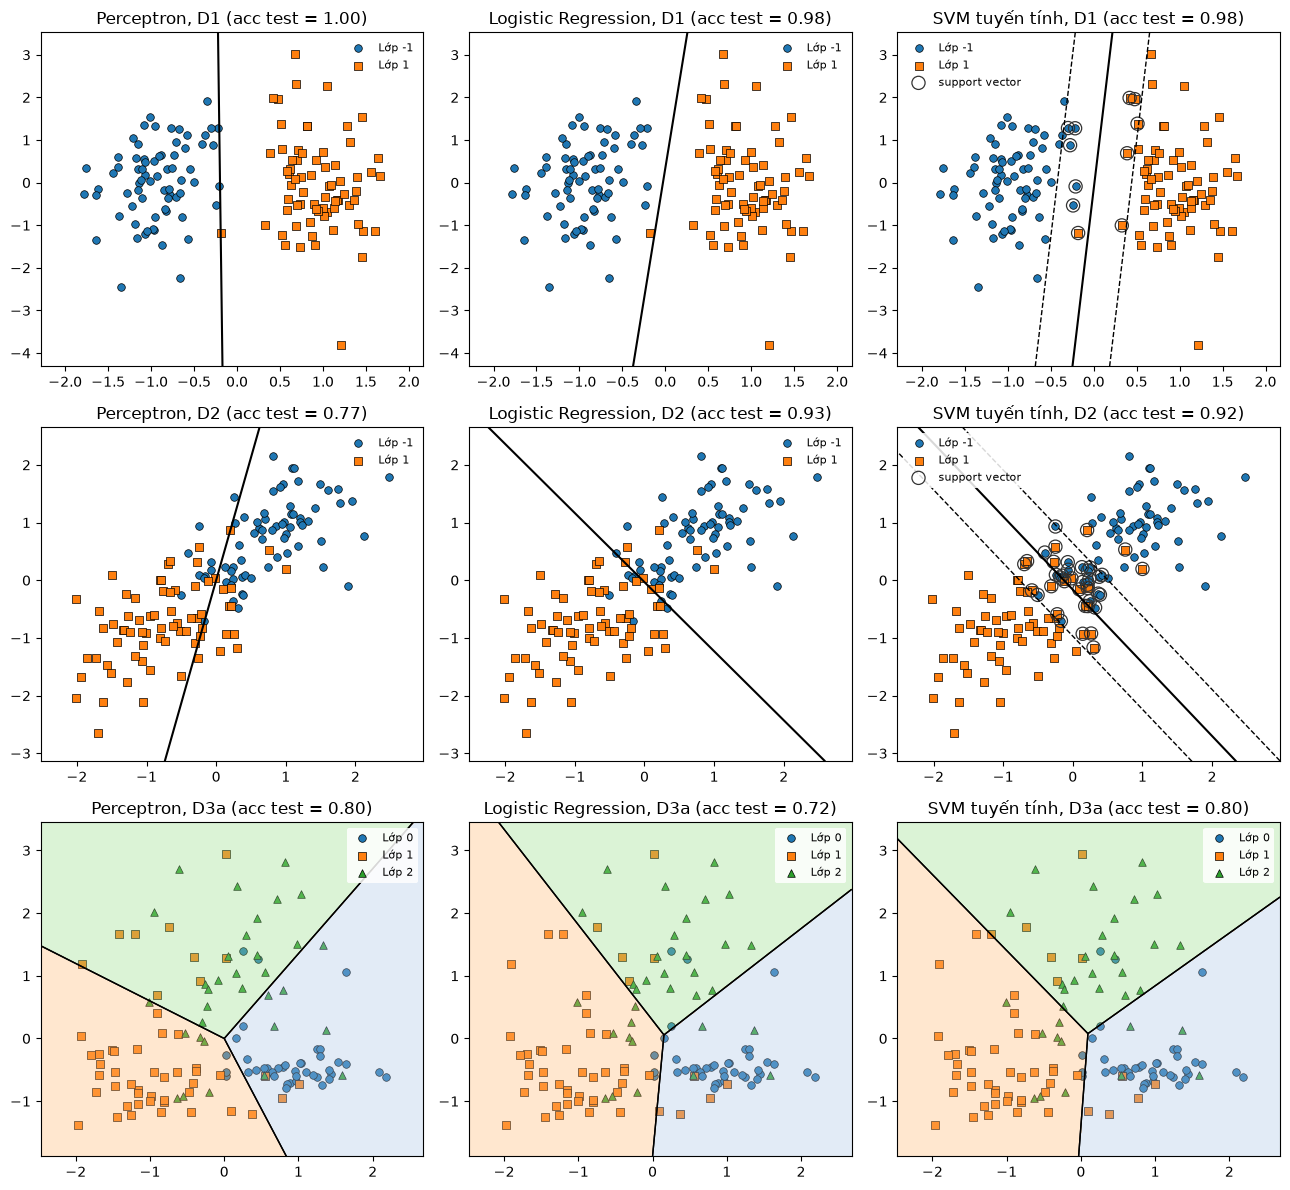

In [15]:
PLOT_SETS = ["D1", "D2", "D3a"]
fitted = {}
fig, axes = plt.subplots(len(PLOT_SETS), len(MODEL_NAMES), figsize=(13, 12))

for r, ds in enumerate(PLOT_SETS):
    X, y = DATASETS[ds]
    X_tr, X_te, y_tr, y_te = split_and_scale(X, y, SEED)
    for c, m in enumerate(MODEL_NAMES):
        clf = make_classifier(m, y_tr).fit(X_tr, y_tr)
        fitted[(ds, m)] = clf
        acc = accuracy_score(y_te, clf.predict(X_te))
        ax = axes[r, c]
        is_binary_svm = m == "SVM tuyến tính" and len(np.unique(y)) == 2
        plot_decision_boundary(ax, clf, X_tr, y_tr, f"{m}, {ds} (acc test = {acc:.2f})", show_margin=is_binary_svm)
        if is_binary_svm:
            sv = clf.support_vector_mask(X_tr, y_tr)
            ax.scatter(X_tr[sv, 0], X_tr[sv, 1], s=90, facecolors="none", edgecolors="#333333",
                       linewidths=0.9, label="support vector")
            ax.legend(fontsize=8, frameon=True, facecolor="white", framealpha=0.85, edgecolor="none")
plt.tight_layout()
plt.show()


### 3.2. Động học Hội tụ (Convergence Dynamics)
Theo dõi quá trình tối ưu qua từng epoch / bước lặp giữa tập dữ liệu tách được ($D_1$) và tập dữ liệu chồng lấn ($D_2$):


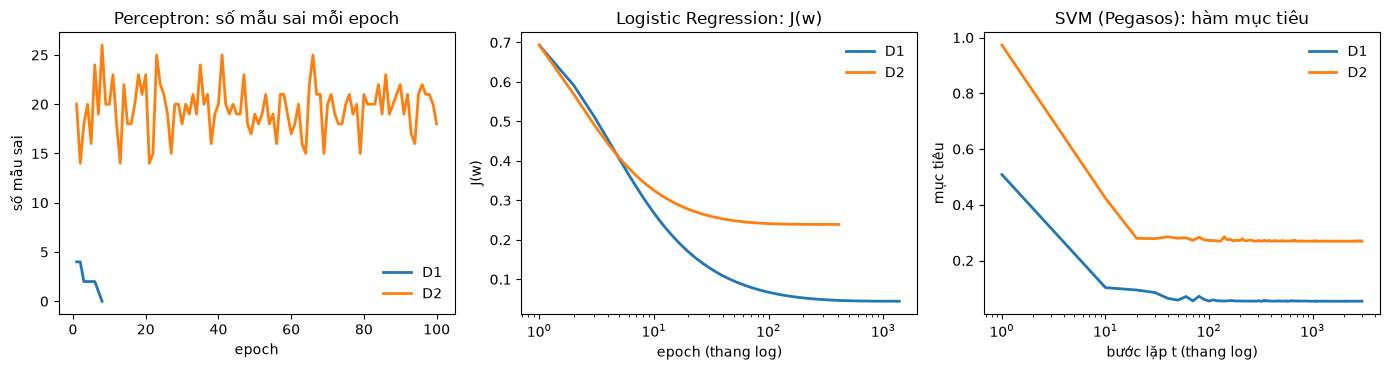

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

for k, ds in enumerate(["D1", "D2"]):
    color = CLASS_COLORS[k]
    p = fitted[(ds, "Perceptron")]
    axes[0].plot(range(1, len(p.errors_) + 1), p.errors_, color=color, lw=2, label=ds)
    lr = fitted[(ds, "Logistic Regression")]
    axes[1].plot(range(1, len(lr.loss_) + 1), lr.loss_, color=color, lw=2, label=ds)
    t, obj = zip(*fitted[(ds, "SVM tuyến tính")].obj_)
    axes[2].plot(t, obj, color=color, lw=2, label=ds)

axes[0].set(title="Perceptron: số mẫu sai mỗi epoch", xlabel="epoch", ylabel="số mẫu sai")
axes[1].set(title="Logistic Regression: J(w)", xlabel="epoch (thang log)", ylabel="J(w)", xscale="log")
axes[2].set(title="SVM (Pegasos): hàm mục tiêu", xlabel="bước lặp t (thang log)", ylabel="mục tiêu", xscale="log")

for ax in axes:
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()


### 3.3. Đánh giá Thống kê qua 10 Lần Chia Train/Test (Repeated Splits)
Để tránh sai lệch do một lần chia dữ liệu ngẫu nhiên, ta lặp lại thực nghiệm trên **10 seed khác nhau (0 đến 9)**. Báo cáo giá trị: **Trung bình ± Độ lệch chuẩn** của Accuracy, Macro F1 và Thời gian huấn luyện (ms).


In [17]:
def evaluate(model_name, ds_name, seed, scale=True):
    """Huấn luyện một mô hình NumPy trên một cách chia, trả về các độ đo trên tập test."""
    X, y = DATASETS[ds_name]
    X_tr, X_te, y_tr, y_te = split_and_scale(X, y, seed, scale=scale)
    clf = make_classifier(model_name, y_tr, seed)
    t0 = time.perf_counter()
    clf.fit(X_tr, y_tr)
    train_ms = 1000 * (time.perf_counter() - t0)
    y_pred = clf.predict(X_te)
    return {
        "impl": "NumPy", 
        "dataset": ds_name, 
        "model": model_name, 
        "seed": seed,
        "accuracy": accuracy_score(y_te, y_pred),
        "f1_macro": f1_score(y_te, y_pred, average="macro"),
        "train_ms": train_ms
    }


def summarize(df, metric, by="dataset", digits=3):
    """Bảng 'trung bình ± độ lệch chuẩn', hàng theo `by`, cột theo mô hình."""
    g = df.groupby([by, "model"], sort=False)[metric]
    cell = g.mean().map(lambda v: f"{v:.{digits}f}") + " ± " + g.std().map(lambda v: f"{v:.{digits}f}")
    return cell.unstack("model")[MODEL_NAMES]


results_np = pd.DataFrame([evaluate(m, ds, s) for ds in DATASETS for m in MODEL_NAMES for s in SEEDS])

print("1. ĐỘ CHÍNH XÁC (ACCURACY) TRÊN TẬP TEST (NUMPY):")
display(summarize(results_np, "accuracy"))

print("\n2. MACRO F1-SCORE TRÊN TẬP TEST (NUMPY):")
display(summarize(results_np, "f1_macro"))

print("\n3. THỜI GIAN HUẤN LUYỆN (ms) (NUMPY):")
display(summarize(results_np, "train_ms", digits=1))


1. ĐỘ CHÍNH XÁC (ACCURACY) TRÊN TẬP TEST (NUMPY):


model,Perceptron,Logistic Regression,SVM tuyến tính
dataset,,,
D1,0.990 ± 0.022,0.992 ± 0.009,0.993 ± 0.009
D2,0.790 ± 0.103,0.898 ± 0.028,0.900 ± 0.018
D3a,0.720 ± 0.067,0.770 ± 0.055,0.781 ± 0.059
D3b,0.980 ± 0.020,0.983 ± 0.011,0.978 ± 0.015



2. MACRO F1-SCORE TRÊN TẬP TEST (NUMPY):


model,Perceptron,Logistic Regression,SVM tuyến tính
dataset,,,
D1,0.990 ± 0.023,0.992 ± 0.009,0.993 ± 0.009
D2,0.772 ± 0.147,0.898 ± 0.028,0.900 ± 0.018
D3a,0.663 ± 0.112,0.753 ± 0.060,0.768 ± 0.063
D3b,0.980 ± 0.020,0.983 ± 0.010,0.978 ± 0.014



3. THỜI GIAN HUẤN LUYỆN (ms) (NUMPY):


model,Perceptron,Logistic Regression,SVM tuyến tính
dataset,,,
D1,11.5 ± 12.5,82.2 ± 13.6,135.5 ± 15.8
D2,56.9 ± 5.1,21.1 ± 4.9,120.4 ± 6.9
D3a,144.3 ± 7.6,37.0 ± 5.8,373.1 ± 11.2
D3b,5.7 ± 1.4,269.9 ± 21.4,348.8 ± 13.4


### 3.4. Khảo sát Ảnh hưởng Quyết định của Chuẩn hóa Đặc trưng
Khảo sát khoảng giá trị cực lớn giữa các đặc trưng Wine, và đo lường độ chính xác trên $D_{3b}$ khi Có chuẩn hóa vs Không chuẩn hóa:


In [18]:
print("Khoảng giá trị của một số đặc trưng tiêu biểu trong tập Wine:")
for j in [12, 4, 10]:
    print(f"  {wine.feature_names[j]:>10s}: {X_d3b[:, j].min():8.2f} đến {X_d3b[:, j].max():8.2f}")

rows = []
for scale in [True, False]:
    for m in MODEL_NAMES:
        for s in SEEDS:
            r = evaluate(m, "D3b", s, scale=scale)
            r["chuẩn hóa"] = "Có" if scale else "Không"
            rows.append(r)

print("\nBẢNG ĐỐI CHIẾU ẢNH HƯỞNG CỦA CHUẨN HÓA TRÊN TẬP WINE D3b:")
display(summarize(pd.DataFrame(rows), "accuracy", by="chuẩn hóa"))


Khoảng giá trị của một số đặc trưng tiêu biểu trong tập Wine:
     proline:   278.00 đến  1680.00
   magnesium:    70.00 đến   162.00
         hue:     0.48 đến     1.71

BẢNG ĐỐI CHIẾU ẢNH HƯỞNG CỦA CHUẨN HÓA TRÊN TẬP WINE D3b:


model,Perceptron,Logistic Regression,SVM tuyến tính
chuẩn hóa,,,
Có,0.980 ± 0.020,0.983 ± 0.011,0.978 ± 0.015
Không,0.617 ± 0.049,0.580 ± 0.111,0.333 ± 0.037


---
## 4. Bài tập Đối chiếu với Thư viện Chuẩn scikit-learn

### 4.1. Ánh xạ Siêu tham số Toán học giữa NumPy và scikit-learn
Ta dùng đúng cách chia tập phân tầng của Phần 3.3 và chuẩn hóa bằng `StandardScaler`. Bảng ánh xạ siêu tham số với $N$ là số mẫu của tập train:

| Mô hình | Bản tự cài đặt NumPy | Bản chuẩn scikit-learn | Quy đổi tương đương |
|---|---|---|---|
| **Perceptron** | `PerceptronNP(rho=1.0, max_epochs=100)` | `Perceptron(eta0=1.0, max_iter=100, random_state=seed)` | Tốc độ học $\rho = \text{eta0} = 1.0$, cùng số epoch tối đa 100. |
| **Logistic Regression** | `LogisticRegressionNP(lam=1e-3, max_epochs=2000)` | `LogisticRegression(C=1/(lam*N), max_iter=2000, solver='lbfgs')` | Khác nhau hệ số điều chuẩn: NumPy phạt $\frac{\lambda}{2}\|\mathbf{w}\|^2$ trên hàm mất mát trung bình, scikit-learn tối ưu $C \sum \text{loss} + \frac{1}{2}\|\mathbf{w}\|^2 \implies C = \frac{1}{\lambda \cdot N}$. Với đa lớp: bọc bằng `OneVsRestClassifier`. |
| **SVM tuyến tính** | `LinearSVMNP(lam=1e-2, n_iters=3000)` | `LinearSVC(loss='hinge', C=1/(lam*N), max_iter=3000)` | scikit-learn mặc định dùng squared hinge loss, cần chỉ định tường minh `loss='hinge'`. Hệ số phạt $C = \frac{1}{\lambda \cdot N}$. |


In [19]:
from sklearn.linear_model import Perceptron as SklearnPerceptron, LogisticRegression as SklearnLogisticRegression
from sklearn.svm import LinearSVC as SklearnLinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler


def make_sklearn_classifier(model_name, n_train, n_classes, seed):
    """Mô hình scikit-learn tương ứng với model_name, cùng siêu tham số với bản NumPy."""
    if model_name == "Perceptron":
        return SklearnPerceptron(
            eta0=PERC_RHO, 
            max_iter=PERC_EPOCHS, 
            tol=0.0, 
            random_state=seed, 
            shuffle=True
        )
    elif model_name == "Logistic Regression":
        # Ánh xạ C = 1 / (λ * N)
        C_lr = 1.0 / (LAM_LR * n_train)
        clf = SklearnLogisticRegression(
            C=C_lr, 
            max_iter=LR_EPOCHS, 
            tol=1e-7, 
            random_state=seed, 
            solver="lbfgs"
        )
        return OneVsRestClassifier(clf) if n_classes > 2 else clf
    elif model_name == "SVM tuyến tính":
        # Ánh xạ C = 1 / (λ * N), chỉ định đúng loss='hinge'
        C_svm = 1.0 / (LAM_SVM * n_train)
        return SklearnLinearSVC(
            loss="hinge", 
            C=C_svm, 
            max_iter=SVM_ITERS, 
            random_state=seed, 
            dual="auto"
        )
    else:
        raise ValueError(f"Tên mô hình không hợp lệ: {model_name}")


In [20]:
def evaluate_sklearn(model_name, ds_name, seed):
    """Như evaluate() ở Phần 3.3 nhưng dùng StandardScaler và mô hình scikit-learn."""
    X, y = DATASETS[ds_name]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=seed
    )
    scaler = StandardScaler().fit(X_tr)
    X_tr = scaler.transform(X_tr)
    X_te = scaler.transform(X_te)
    
    n_train = len(y_tr)
    n_classes = len(np.unique(y_tr))
    clf = make_sklearn_classifier(model_name, n_train, n_classes, seed)
    
    t0 = time.perf_counter()
    clf.fit(X_tr, y_tr)
    train_ms = 1000 * (time.perf_counter() - t0)
    
    y_pred = clf.predict(X_te)
    return {
        "impl": "scikit-learn", 
        "dataset": ds_name, 
        "model": model_name, 
        "seed": seed,
        "accuracy": accuracy_score(y_te, y_pred),
        "f1_macro": f1_score(y_te, y_pred, average="macro"),
        "train_ms": train_ms
    }


results_sk = pd.DataFrame([evaluate_sklearn(m, ds, s) for ds in DATASETS for m in MODEL_NAMES for s in SEEDS])

print("1. ĐỘ CHÍNH XÁC TRÊN TẬP TEST (SCIKIT-LEARN):")
display(summarize(results_sk, "accuracy"))

print("\n2. THỜI GIAN HUẤN LUYỆN (ms) (SCIKIT-LEARN):")
display(summarize(results_sk, "train_ms", digits=1))


1. ĐỘ CHÍNH XÁC TRÊN TẬP TEST (SCIKIT-LEARN):


model,Perceptron,Logistic Regression,SVM tuyến tính
dataset,,,
D1,0.985 ± 0.012,0.992 ± 0.009,0.993 ± 0.009
D2,0.872 ± 0.027,0.898 ± 0.028,0.898 ± 0.020
D3a,0.765 ± 0.075,0.770 ± 0.055,0.776 ± 0.063
D3b,0.970 ± 0.018,0.980 ± 0.016,0.976 ± 0.015



2. THỜI GIAN HUẤN LUYỆN (ms) (SCIKIT-LEARN):


model,Perceptron,Logistic Regression,SVM tuyến tính
dataset,,,
D1,3.2 ± 0.6,10.2 ± 7.7,3.7 ± 6.3
D2,2.1 ± 0.4,6.1 ± 0.7,1.7 ± 0.5
D3a,3.0 ± 0.5,21.5 ± 6.2,1.6 ± 0.2
D3b,4.9 ± 0.7,40.5 ± 3.7,2.5 ± 0.6


### 4.2. Bảng So sánh Tổng hợp giữa NumPy và scikit-learn
Ghép nối toàn bộ kết quả thực nghiệm từ 10 lần chia, tính toán:
1. **Accuracy trung bình** của bản NumPy và scikit-learn.
2. **Độ lệch chính xác**: $\Delta \text{Acc} = \text{Acc}_{\text{NumPy}} - \text{Acc}_{\text{scikit-learn}}$.
3. **Thời gian huấn luyện trung bình** và **Tỉ lệ thời gian (Speedup Ratio)**.


In [21]:
# Ghép dữ liệu kết quả từ cả hai cài đặt
df_combined = pd.concat([results_np, results_sk], ignore_index=True)

# Tính giá trị trung bình theo từng cặp (dataset, model, impl)
mean_acc = df_combined.groupby(["dataset", "model", "impl"], sort=False)["accuracy"].mean().unstack("impl")
mean_time = df_combined.groupby(["dataset", "model", "impl"], sort=False)["train_ms"].mean().unstack("impl")

# Xây dựng bảng so sánh tổng hợp
comparison_table = pd.DataFrame({
    "Accuracy (NumPy)": mean_acc["NumPy"].map(lambda v: f"{v:.3f}"),
    "Accuracy (scikit-learn)": mean_acc["scikit-learn"].map(lambda v: f"{v:.3f}"),
    "Chênh lệch (NP - SK)": (mean_acc["NumPy"] - mean_acc["scikit-learn"]).map(lambda v: f"{v:+.3f}"),
    "Thời gian NP (ms)": mean_time["NumPy"].map(lambda v: f"{v:.1f}"),
    "Thời gian SK (ms)": mean_time["scikit-learn"].map(lambda v: f"{v:.1f}"),
    "Tỉ lệ thời gian (NP / SK)": (mean_time["NumPy"] / mean_time["scikit-learn"]).map(lambda v: f"{v:.1f}x"),
})

print("BẢNG SO SÁNH TỔNG HỢP HIỆU NĂNG GIỮA NUMPY VÀ SCIKIT-LEARN:")
display(comparison_table)


BẢNG SO SÁNH TỔNG HỢP HIỆU NĂNG GIỮA NUMPY VÀ SCIKIT-LEARN:


Accuracy (NumPy) Accuracy (scikit-learn)  \
dataset model                                                          
D1      Perceptron                     0.990                   0.985   
        Logistic Regression            0.992                   0.992   
        SVM tuyến tính                 0.993                   0.993   
D2      Perceptron                     0.790                   0.872   
        Logistic Regression            0.898                   0.898   
        SVM tuyến tính                 0.900                   0.898   
D3a     Perceptron                     0.720                   0.765   
        Logistic Regression            0.770                   0.770   
        SVM tuyến tính                 0.781                   0.776   
D3b     Perceptron                     0.980                   0.970   
        Logistic Regression            0.983                   0.980   
        SVM tuyến tính                 0.978                   0.976   

                            Chênh lệch (NP - SK) Thời gian NP (ms)  \
dataset model                                                        
D1      Perceptron                        +0.005              11.5   
        Logistic Regression               +0.000              82.2   
        SVM tuyến tính                    +0.000             135.5   
D2      Perceptron                        -0.082              56.9   
        Logistic Regression               +0.000              21.1   
        SVM tuyến tính                    +0.002             120.4   
D3a     Perceptron                        -0.044             144.3   
        Logistic Regression               +0.000              37.0   
        SVM tuyến tính                    +0.006             373.1   
D3b     Perceptron                        +0.009               5.7   
        Logistic Regression               +0.004             269.9   
        SVM tuyến tính                    +0.002             348.8   

                            Thời gian SK (ms) Tỉ lệ thời gian (NP / SK)  
dataset model                                                            
D1      Perceptron                        3.2                      3.6x  
        Logistic Regression              10.2                      8.1x  
        SVM tuyến tính                    3.7                     36.8x  
D2      Perceptron                        2.1                     27.1x  
        Logistic Regression               6.1                      3.5x  
        SVM tuyến tính                    1.7                     69.4x  
D3a     Perceptron                        3.0                     47.4x  
        Logistic Regression              21.5                      1.7x  
        SVM tuyến tính                    1.6                    228.9x  
D3b     Perceptron                        4.9                      1.2x  
        Logistic Regression              40.5                      6.7x  
        SVM tuyến tính                    2.5                    141.7x

### 4.3. Phân tích Góc lệch Siêu phẳng qua Độ đo Cosine Similarity ($D_1$ và $D_2$)

#### Cơ sở Toán học:
Hai siêu phẳng phân cách trùng nhau khi và chỉ khi hai vector pháp tuyến mở rộng $\mathbf{w} \in \mathbb{R}^{d+1}$ của chúng **cùng phương cùng hướng**:
$$\text{Cosine Similarity} = \frac{\mathbf{w}_{\text{NP}}^\top \mathbf{w}_{\text{SK}}}{\lVert \mathbf{w}_{\text{NP}} \rVert \cdot \lVert \mathbf{w}_{\text{SK}} \rVert}$$
* $\text{Cosine} = 1.0$: Hai siêu phẳng hoàn toàn trùng khít về mặt hình học trong không gian đặc trưng.
* Trong scikit-learn, vector trọng số được ghép từ `coef_` và `intercept_`: $\mathbf{w}_{\text{SK}} = [\texttt{coef\_}[0], \texttt{intercept\_}[0]]^\top$.


In [22]:
cosine_results = []

for ds in ["D1", "D2"]:
    X, y = DATASETS[ds]
    X_tr, X_te, y_tr, y_te = split_and_scale(X, y, seed=0)
    n_train = len(y_tr)
    
    for m in MODEL_NAMES:
        # Huấn luyện bản NumPy trên seed 0
        clf_np = MODEL_FACTORIES[m](seed=0).fit(X_tr, y_tr)
        w_np = clf_np.w_
        
        # Huấn luyện bản scikit-learn trên cùng dữ liệu và seed 0
        clf_sk = make_sklearn_classifier(m, n_train, n_classes=2, seed=0).fit(X_tr, y_tr)
        w_sk = np.append(clf_sk.coef_.ravel(), clf_sk.intercept_[0])
        
        # Tính Cosine Similarity
        cos_sim = np.dot(w_np, w_sk) / (np.linalg.norm(w_np) * np.linalg.norm(w_sk))
        
        cosine_results.append({
            "Tập dữ liệu": ds,
            "Mô hình": m,
            "w (NumPy)": np.round(w_np, 3),
            "w (scikit-learn)": np.round(w_sk, 3),
            "Cosine Similarity": round(cos_sim, 4)
        })

df_cosine = pd.DataFrame(cosine_results)
print("BẢNG ĐỘ TƯƠNG ĐỒNG COSINE GIỮA VECTOR w CỦA NUMPY VÀ SCIKIT-LEARN:")
display(df_cosine[["Tập dữ liệu", "Mô hình", "Cosine Similarity"]])


BẢNG ĐỘ TƯƠNG ĐỒNG COSINE GIỮA VECTOR w CỦA NUMPY VÀ SCIKIT-LEARN:


,Tập dữ liệu,Mô hình,Cosine Similarity
0,D1,Perceptron,0.9981
1,D1,Logistic Regression,1.0000
2,D1,SVM tuyến tính,1.0000
3,D2,Perceptron,0.9228
4,D2,Logistic Regression,1.0000
5,D2,SVM tuyến tính,0.9995


---
## 5. Câu hỏi thảo luận

### Câu 1: Trên D1, ba mô hình đều phân lớp tốt nhưng ranh giới khác nhau. Mô hình nào cho lề lớn nhất? Vì sao Perceptron không đảm bảo điều đó?
* **Mô hình cho lề lớn nhất:** **SVM tuyến tính** (Linear SVM).
* **Vì sao Perceptron không đảm bảo điều đó:**
  * Perceptron chỉ tìm kiếm một siêu phẳng bất kỳ thỏa mãn điều kiện phân lớp đúng mọi mẫu ($y_i \mathbf{w}^\top \tilde{\mathbf{x}}_i > 0$). Ngay khi không còn mẫu lỗi ($n\_err = 0$), thuật toán dừng cập nhật lập tức mà không quan tâm khoảng cách tới các điểm dữ liệu. Do đó ranh giới của Perceptron có thể nằm rất sát một trong hai lớp.
  * Ngược lại, SVM chủ động giải bài toán tối ưu hình học nhằm tối đa hóa độ rộng lề $2 / \lVert \mathbf{w}_0 \rVert$, ép siêu phẳng phải nằm chính giữa hai lớp.

---

### Câu 2: Trên D2, vì sao Perceptron không dừng sớm và kết quả phụ thuộc vào epoch cuối? Logistic Regression và SVM xử lý dữ liệu không tách được như thế nào?
* **Vì sao Perceptron không dừng sớm:** D2 có hai lớp chồng lấn (không tách được tuyến tính). Trong mọi epoch luôn có ít nhất một mẫu bị sai ($n\_err > 0$), do đó điều kiện dừng $n\_err == 0$ không bao giờ thỏa mãn và thuật toán buộc phải chạy hết `max_epochs`.
* **Vì sao kết quả phụ thuộc epoch cuối:** Do Perceptron cập nhật online từng mẫu lỗi một, vector trọng số $\mathbf{w}$ bị xoay liên tục. Kết quả nghiệm cuối cùng phụ thuộc ngẫu nhiên vào mẫu lỗi được duyệt ở những bước cuối cùng của epoch 100.
* **Cách xử lý của Logistic Regression và SVM:**
  * **Logistic Regression:** Tối thiểu hóa hàm mất mát Cross-Entropy trơn và lồi trên toàn bộ tập dữ liệu kèm số hạng phạt $L_2$. Kể cả khi có mẫu chồng lấn, gradient vẫn hướng về điểm cực tiểu toàn cục duy nhất, tìm ra ranh giới cân bằng xác suất tối ưu.
  * **SVM lề mềm:** Dùng hàm mất mát Hinge Loss cho phép các mẫu được vi phạm lề (hoặc nằm sai phía ranh giới) với một chi phí phạt xác định. Thuật toán tìm sự cân bằng giữa tối đa hóa lề và tối thiểu hóa tổng độ vi phạm lề.

---

### Câu 3: Với $\mathbf{w}$ khởi tạo bằng 0, hệ số học $\rho$ của Perceptron có làm thay đổi ranh giới quyết định không? Giải thích.
* **Trả lời:** **KHÔNG làm thay đổi ranh giới quyết định**.
* **Giải thích:**
  * Khi $\mathbf{w}_0 = \mathbf{0}$, sau các bước cập nhật trên các mẫu lỗi, vector trọng số có dạng:
    $$\mathbf{w} = \sum_{i \in \text{lỗi}} \rho y_i \tilde{\mathbf{x}}_i = \rho \sum_{i \in \text{lỗi}} y_i \tilde{\mathbf{x}}_i = \rho \, \mathbf{w}_{\text{chuẩn}}$$
  * Hệ số $\rho > 0$ chỉ đóng vai trò nhân độ dài của vector $\mathbf{w}$ lên $\rho$ lần mà không làm thay đổi phương hướng của nó.
  * Phương trình ranh giới quyết định là $\mathbf{w}^\top \tilde{\mathbf{x}} = 0 \iff \rho (\mathbf{w}_{\text{chuẩn}}^\top \tilde{\mathbf{x}}) = 0 \iff \mathbf{w}_{\text{chuẩn}}^\top \tilde{\mathbf{x}} = 0$. Tương tự, quy tắc dự đoán $\operatorname{sign}(\mathbf{w}^\top \tilde{\mathbf{x}}) = \operatorname{sign}(\rho \, \mathbf{w}_{\text{chuẩn}}^\top \tilde{\mathbf{x}}) = \operatorname{sign}(\mathbf{w}_{\text{chuẩn}}^\top \tilde{\mathbf{x}})$ là không đổi.

---

### Câu 4: Vì sao chuẩn hóa ảnh hưởng mạnh đến Logistic Regression và SVM ở Phần 3.4?
* **Thang đo chênh lệch:** Trong tập Wine, đặc trưng `Proline` có giá trị lên đến 1680, trong khi các đặc trưng khác chỉ từ 0.1 đến 5.
* **Cơ chế điều chuẩn $L_2$ ($\frac{\lambda}{2}\|\mathbf{w}\|^2$):**
  * Điều chuẩn $L_2$ phạt đều bình phương mọi trọng số $w_j$ với cùng một hệ số $\lambda$.
  * Với đặc trưng có thang đo nhỏ, mô hình cần một trọng số $w_j$ đủ lớn để tạo ra ảnh hưởng lên kết quả. Nhưng trọng số lớn lại bị số hạng phạt $L_2$ ép mạnh về 0.
  * Ngược lại, đặc trưng có thang đo cực lớn chỉ cần một trọng số $w_j$ rất bé đã chi phối hoàn toàn hàm mục tiêu. Kết quả là mô hình bỏ qua các đặc trưng thang đo nhỏ và suy giảm nghiêm trọng độ chính xác.
* **Khoảng cách hình học trong SVM:** Độ rộng lề dựa trên chuẩn Euclid $\lVert \mathbf{w} \rVert$. Thang đo bất đối xứng làm biến dạng toàn bộ không gian khoảng cách Euclid.

---

### Câu 5: Trong one-vs-rest, các giá trị $g_k(\mathbf{x})$ của Perceptron có so sánh được với nhau không? Đề xuất cách khắc phục.
* **Trả lời:** **KHÔNG thể so sánh trực tiếp một cách công bằng**.
* **Lý do:**
  * Giá trị $g_k(\mathbf{x}) = \mathbf{w}_k^\top \tilde{\mathbf{x}}$ phụ thuộc trực tiếp vào độ dài $\lVert \mathbf{w}_k \rVert$.
  * Lớp nào có dữ liệu khó phân tách hơn sẽ bị cập nhật lỗi nhiều lần hơn, dẫn đến độ dài $\lVert \mathbf{w}_k \rVert$ lớn hơn đáng kể. Khi đó giá trị $g_k(\mathbf{x})$ của lớp này sẽ lớn hơn về mặt biên độ chỉ vì vector trọng số của nó dài hơn, chứ không đồng nghĩa mô hình tự tin hơn.
* **Cách khắc phục:**
  1. **Chuẩn hóa hình học vector pháp tuyến:** Chia cho chuẩn Euclid của các trọng số đặc trưng:
     $$g_k^{\text{norm}}(\mathbf{x}) = \frac{\mathbf{w}_k^\top \tilde{\mathbf{x}}}{\lVert \mathbf{w}_{k, 1:d} \rVert}$$
     Giá trị thu được chính là khoảng cách hình học thực tế từ điểm $\mathbf{x}$ đến siêu phẳng của lớp $k$.
  2. **Hiệu chuẩn xác suất (Platt Scaling):** Dùng hàm Sigmoid chuyển đổi điểm số $g_k(\mathbf{x})$ về xác suất trước khi so sánh.

---

### Câu 6: Bản SVM ở đây gộp bias vào $\mathbf{w}$ nên bias cũng bị điều chuẩn. Điều này thay đổi bài toán so với chuẩn như thế nào? Khi nào ảnh hưởng đáng kể?
* **Thay đổi so với chuẩn:**
  * Trong SVM chuẩn (Cortes & Vapnik 1995), hàm mục tiêu chỉ phạt độ dài vector pháp tuyến $\frac{1}{2}\lVert \mathbf{w}_0 \rVert^2$, hệ số chệch $b$ tự do không bị phạt.
  * Khi gộp bias vào vector mở rộng $\tilde{\mathbf{w}} = [\mathbf{w}_0; b]$, số hạng phạt trở thành $\frac{\lambda}{2}\lVert \mathbf{w}_0 \rVert^2 + \frac{\lambda}{2}b^2$. Việc phạt $b^2$ ép siêu phẳng có xu hướng phải đi qua gần gốc tọa độ $\mathbf{0}$.
* **Khi nào ảnh hưởng đáng kể:**
  * Khi dữ liệu nằm xa gốc tọa độ và siêu phẳng phân cách tối ưu đòi hỏi độ chệch $b$ lớn. Khi đó việc phạt $b^2$ sẽ kéo lệch siêu phẳng về phía gốc tọa độ, làm giảm độ chính xác phân loại.
  * *Lưu ý:* Khi dữ liệu đã được chuẩn hóa Z-score (tâm dữ liệu nằm tại gốc tọa độ $\mathbf{0}$), siêu phẳng tối ưu tự nhiên đi qua gần gốc tọa độ ($b \approx 0$), do đó việc phạt bias hầu như không gây ảnh hưởng tiêu cực.

---

### Câu 7: Logistic Regression cho xác suất đầu ra, SVM thì không. Nêu một tình huống thực tế điều này quan trọng.
* **Tình huống thực tế:** **Hệ thống chẩn đoán y khoa hỗ trợ bác sĩ phát hiện tế bào ung thư ác tính** (hoặc Hệ thống phê duyệt tín dụng ngân hàng).
* **Ý nghĩa:**
  * SVM chỉ đưa ra nhãn cứng (+1 hoặc -1). Bác sĩ không thể biết mô hình chắc chắn đến mức nào.
  * Logistic Regression cung cấp xác suất định lượng rõ ràng:
    * Bệnh nhân X có xác suất ung thư $98\% \implies$ Mức độ chắc chắn rất cao, ưu tiên can thiệp điều trị khẩn cấp.
    * Bệnh nhân Y có xác suất ung thư $51\% \implies$ Mẫu nằm sát ranh giới tranh chấp, bác sĩ nhận biết để chỉ định làm thêm sinh thiết chuyên sâu.
  * Ngoài ra, xác suất cho phép **thay đổi linh hoạt ngưỡng quyết định (Threshold Moving)**: Trong y tế, vì việc bỏ sót ca ung thư (False Negative) nguy hiểm hơn nhiều so với việc chẩn đoán nhầm (False Positive), ta có thể hạ ngưỡng cảnh báo xuống $0.2$ thay vì cố định tại $0.5$.

---

### Câu 8: So sánh D3a và D3b: Thêm đặc trưng làm hiệu năng thay đổi thế nào? Vì sao?
* **Sự thay đổi hiệu năng:**
  * Trên $D_{3a}$ (chỉ dùng 2 đặc trưng: `alcohol`, `malic acid`), Test Accuracy của các mô hình chỉ đạt từ **$72\% - 78\%$**.
  * Trên $D_{3b}$ (đầy đủ 13 đặc trưng có chuẩn hóa), Test Accuracy tăng vọt lên **$97\% - 98\%$** (gần như phân loại chính xác tuyệt đối).
* **Vì sao:**
  * **Định lý Cover về khả năng phân tách (Cover's Theorem):** Khi chiếu dữ liệu lên một không gian đặc trưng có số chiều cao hơn ($d = 13$ so với $d = 2$), xác suất để tập dữ liệu trở nên tách được tuyến tính bởi một siêu phẳng tăng lên đáng kể.
  * Trong không gian 2D, các mẫu của 3 giống nho bị chồng lấn và che khuất lẫn nhau khi nhìn từ mặt phẳng 2 thuộc tính ban đầu. Nhưng trong không gian 13 chiều, các đặc trưng bổ sung (như `flavanoids`, `proline`, `color_intensity`) cung cấp thêm nhiều chiều thông tin phân tách trực giao mạnh mẽ, cho phép siêu phẳng 13 chiều dễ dàng cô lập từng lớp.


---
## 6. Tài liệu tham khảo

1. **K. Wickström**, *Pattern Recognition Handbook*, Sổ tay bài giảng học phần FYS-3012 Pattern Recognition, UiT The Arctic University of Norway. GitHub, MIT License. https://github.com/Wickstrom/pattern-recognition-handbook
2. **F. Rosenblatt**, "The perceptron: A probabilistic model for information storage and organization in the brain," *Psychological Review*, vol. 65, no. 6, pp. 386–408, 1958. doi:10.1037/h0042519
3. **C. Cortes and V. Vapnik**, "Support-vector networks," *Machine Learning*, vol. 20, pp. 273–297, 1995. doi:10.1007/BF00994018
4. **C. M. Bishop**, *Pattern Recognition and Machine Learning*. Springer, 2006. Mục 4.1.7 (Thuật toán Perceptron), Mục 4.3.2 (Hồi quy Logistic), Mục 7.1 (SVM lề cực đại).
5. **S. Shalev-Shwartz, Y. Singer, N. Srebro, and A. Cotter**, "Pegasos: Primal estimated sub-gradient solver for SVM," *Mathematical Programming*, vol. 127, no. 1, pp. 3–30, 2011. doi:10.1007/s10107-010-0420-4
6. **F. Pedregosa et al.**, "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.
7. **S. Aeberhard and M. Forina**, "Wine," UCI Machine Learning Repository, 1991. doi:10.24432/C5PC7J
